# MuZero-Style Models and Monte Carlo Tree Search

Portfolio packaging for Behrad Mazaheri. Original course/template credits below are retained; individual contributions are unverified.

**Static review only; no cells executed.** Historical outputs are preserved, not independently reproduced. Read README and REVIEW before citing results. Source cell indices in documentation are zero-based before this banner.

Educational MuZero-style implementation rather than a full paper reproduction. The fallback changes the episode horizon. Search includes root noise; distinguish exploratory training returns from a fixed evaluation policy. The custom frame stack uses an internal API, not a complete standard Gymnasium wrapper contract.


<h1 style="font-size: 42px; text-align: center;">HW5: Monte Carlo Tree Search & Naive Search</h1>

> **Full Name:** `<behrad mazaheri>`  
> **Student ID:** `<[student ID removed]>`

---

## 🎯 Learning Objectives

By the end of this notebook, you will:

1. Understand the **theoretical foundations** of Monte Carlo Tree Search (MCTS) and how it differs from naive (brute-force) lookahead.
2. Be able to **implement MuZero-style learned dynamics** for planning without a known environment model.
3. Combine learned representation, dynamics, and prediction networks with tree search.
4. Compare empirical performance of **MCTS vs. naive depth search vs. no search** on `CartPole-v0`.

---

## 📚 Why Search Matters in Reinforcement Learning

Classical model-free RL (e.g., DQN, PPO) directly maps observations to actions. While powerful, these methods don't *plan*. 
Classical model-based RL plans using a **given** simulator. But what if the simulator is unavailable or too expensive?

**MuZero** (Schrittwieser et al., 2019) solves this by *learning* a model in a latent space, then planning with MCTS in that latent space. This achieved state-of-the-art on Atari, Go, Chess, and Shogi with a single algorithm.

This notebook is a minimal but faithful implementation of these ideas on CartPole.

> 🧠 **What you must implement** is marked clearly with `# TODO`. Everything else (data plumbing, training loop scaffolding, plots) is provided.

## 📖 Part 1 — Theoretical Background

### 1.1 Monte Carlo Tree Search (MCTS)

MCTS builds a search tree incrementally by performing $N$ simulations from the root. Each simulation consists of four phases:

| Phase | Description |
|-------|-------------|
| **Selection** | Starting at the root, repeatedly choose children using a tree policy (PUCT/UCB) until reaching a leaf. |
| **Expansion** | At the leaf, query the dynamics + prediction networks to create child nodes for each action. |
| **Simulation/Evaluation** | Instead of random rollouts (classical MCTS), MuZero uses the value head directly. |
| **Backpropagation** | Propagate the value estimate back along the visited path, updating visit counts and Q-values. |

#### The PUCT formula (used by MuZero / AlphaZero)

At each internal node, the action chosen is:

$$a^* = \arg\max_a \Big[ Q(s, a) + P(s, a) \cdot \frac{\sqrt{N(s)}}{1 + N(s, a)} \cdot \Big( c_1 + \log \frac{N(s) + c_2 + 1}{c_2} \Big) \Big]$$

where:
- $Q(s,a)$ = mean value backed up through edge $(s,a)$
- $P(s,a)$ = prior probability from the prediction network
- $N(s)$, $N(s,a)$ = visit counts at the node and edge
- $c_1 = 1.25$, $c_2 = 19652$ (standard MuZero hyperparameters)

The Q-values are **min-max normalized** across the tree to keep the formula well-scaled across different reward magnitudes.

### 1.2 Naive Depth Search

Naive search enumerates **every** action sequence of length $d$. For action space $|A|$ and depth $d$, the cost is $O(|A|^d)$. For each leaf, we compute:

$$\text{Return}(a_1, \dots, a_d) = \sum_{t=0}^{d-1} \gamma^t r_t + \gamma^d V(s_d)$$

and pick the first action of the best sequence.

### 1.3 MuZero's Three Networks

| Network | Signature | Purpose |
|---------|-----------|---------|
| **Representation** $h_\theta$ | $o \mapsto s_0$ | Encode raw observation into latent state |
| **Dynamics** $g_\theta$ | $(s_t, a_t) \mapsto (s_{t+1}, r_t)$ | Predict next latent state and reward |
| **Prediction** $f_\theta$ | $s_t \mapsto (\pi_t, v_t)$ | Predict policy prior and value |

All three are trained **jointly end-to-end** by unrolling the model for $K$ steps and matching predictions to targets stored in a replay buffer.

### 1.4 Loss Function (MuZero)

For a sampled sub-trajectory unrolled $K$ steps:

$$\mathcal{L}(\theta) = \sum_{k=0}^{K} \Big[ \mathcal{L}^p(\pi^{\text{MCTS}}_k, \pi^\theta_k) + \mathcal{L}^v(z_k, v^\theta_k) + \mathcal{L}^r(u_k, r^\theta_k) \Big]$$

where $z_k$ is the n-step return target and $u_k$ the observed reward.

> ⚠️ **Common pitfall:** Use **MSE** for scalar value/reward targets, and **cross-entropy** between distributions for the policy.

## 🛠️ Part 2 — Step-by-Step Implementation Guide

The notebook is organized as follows. Sections marked **(provided)** require no implementation; sections marked **(TODO)** are for you to complete.

1. **Imports & Setup** *(provided)*
2. **Environment Wrapper** *(provided)*
3. **Replay Buffer** — *(partial TODO: n-step return computation)*
4. **Neural Networks** — *(TODO: all three networks)*
5. **Search Algorithms**
   - MinMax Normalizer *(provided)*
   - Tree Node *(provided)*
   - **MCTS** *(TODO: selection, expansion, backprop, PUCT)*
   - **Naive depth search** *(TODO)*
6. **Agent** — *(TODO: act, initial_inference, recurrent_step)*
7. **Training Loop** *(provided, but you must wire your code in)*
8. **Comparison Experiment** *(provided)*

Let's go!

## 1️⃣ Imports & Setup *(provided)*

In [12]:
import math
import time
import random
import warnings
from collections import deque

import numpy as np

# Compatibility fix for old gym with NumPy >= 2.0
if not hasattr(np, "bool8"):
    np.bool8 = np.bool_


try:
    import gym
except ImportError:
    import gymnasium as gym
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import clear_output

warnings.filterwarnings("ignore", category=DeprecationWarning)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float32
print(f"Using device: {device}")


def make_cartpole_env():
    """Create CartPole with a small compatibility fallback.

    The homework text uses CartPole-v0. Newer Gymnasium installations may only
    expose CartPole-v1, so we try v0 first and fall back to v1.
    """
    try:
        return gym.make("CartPole-v0")
    except Exception:
        return gym.make("CartPole-v1")

Using device: cuda


## 2️⃣ Environment Wrapper *(provided)*

Stacks the last `history_len` observations into a single flat vector.

In [13]:
class FrameStackWrapper(gym.Wrapper):
    def __init__(self, env, history_len=3):
        super().__init__(env)
        self.history_len = history_len
        self.obs_dim = env.observation_space.shape[0]
        self.num_actions = env.action_space.n
        self.frames = deque(maxlen=history_len)

    def _stacked(self):
        stacked = np.zeros((self.history_len, self.obs_dim), dtype=np.float32)
        n = len(self.frames)
        if n > 0:
            stacked[self.history_len - n:] = np.array(self.frames)
        return stacked.flatten().reshape(1, -1)

    def reset(self):
        self.episode_return = 0.0
        self.frames.clear()
        out = self.env.reset()
        # Gym/Gymnasium compatibility: reset may return obs or (obs, info).
        obs = out[0] if isinstance(out, tuple) else out
        self.frames.append(np.asarray(obs, dtype=np.float32))
        return self._stacked()

    def step(self, action):
        out = self.env.step(action)
        # Gymnasium returns 5 values; older Gym returns 4.
        if isinstance(out, tuple) and len(out) == 5:
            next_obs, reward, terminated, truncated, info = out
            done = bool(terminated or truncated)
        else:
            next_obs, reward, done, info = out
            done = bool(done)
        self.frames.append(np.asarray(next_obs, dtype=np.float32))
        self.episode_return += float(reward)
        if done:
            info = dict(info)
            info["return"] = self.episode_return
        return self._stacked(), float(reward), done, info


class EnvironmentRunner:
    """Runs an episode and collects a full trajectory."""
    def __init__(self, env):
        self.env = env
        self.num_actions = env.action_space.n
        self.episode_returns = []

    def run_episode(self, agent, max_steps=500):
        observations, actions, rewards, dones, policies, values = [], [], [], [], [], []
        obs = self.env.reset()
        observations.append(torch.tensor(obs, dtype=dtype))

        done = False
        steps = 0
        while not done and steps < max_steps:
            obs_t = torch.tensor(obs, dtype=dtype, device=device)
            action, policy, value = agent.act(obs_t)
            next_obs, reward, done, _ = self.env.step(action)

            observations.append(torch.tensor(next_obs, dtype=dtype))
            actions.append(int(action))
            policies.append(torch.tensor(policy, dtype=dtype))
            values.append(torch.tensor([float(value)], dtype=dtype))
            rewards.append(torch.tensor([float(reward)], dtype=dtype))
            dones.append(done)

            obs = next_obs
            steps += 1

        ep_return = float(sum(r.item() for r in rewards))
        self.episode_returns.append(ep_return)

        return {
            "obs": observations,
            "actions": actions,
            "rewards": rewards,
            "dones": dones,
            "policies": policies,
            "values": values,
            "length": len(observations),
        }

## 3️⃣ Replay Buffer

The scaffold is provided, but you must implement the **n-step return computation** inside `_sample_one`.

### What you need to compute

For each step $t$ in the sampled sub-trajectory, the n-step bootstrapped return is:

$$z_t = \sum_{i=0}^{n-1} \gamma^i r_{t+i} + \gamma^n V(s_{t+n})$$

If $t+n$ exceeds the trajectory length, the bootstrap value $V(s_{t+n})$ should be **0** (terminal). Be careful with index bounds!

In [14]:
class ReplayBuffer:
    def __init__(self, capacity, num_actions):
        self.capacity = capacity
        self.num_actions = num_actions
        self.memory = []
        self.position = 0

    def __len__(self):
        return len(self.memory)

    def add(self, trajectory):
        if len(self.memory) < self.capacity:
            self.memory.append(trajectory)
        else:
            self.memory[self.position] = trajectory
        self.position = (self.position + 1) % self.capacity

    def _sample_one(self, k, n, gamma):
        """
        Returns a dict with keys:
          - 'obs':     observation tensor at the start step
          - 'actions': list of length k (ints)
          - 'rewards': list of length k (each shape [1])
          - 'pi':      list of length k+1 (each shape [num_actions])
          - 'return':  list of length k+1 (each shape [1]) — the n-step targets

        The starting index is chosen uniformly at random in [0, T-1].
        """
        traj = self.memory[np.random.randint(len(self.memory))]
        T = traj["length"]
        last_idx = T - 1                       # index of terminal/last observation
        start = np.random.randint(T)

        obs = traj["obs"][start]
        returns, pis, action_list, rewards_list = [], [], [], []

        for step in range(start, start + k + 1):
            # ------------------------------------------------------------
            # n-step bootstrapped value target
            # z_t = r_t + gamma r_{t+1} + ... + gamma^(n-1) r_{t+n-1}
            #       + gamma^n V(s_{t+n})
            # Rewards are stored by transition index: rewards[j] is the
            # reward from observation j to observation j+1.
            # ------------------------------------------------------------
            total = torch.zeros(1, dtype=dtype, device=device)
            bootstrap_idx = step + n

            max_reward_idx = min(last_idx, bootstrap_idx)
            if step < last_idx:
                for idx in range(step, max_reward_idx):
                    if idx < len(traj["rewards"]):
                        discount = gamma ** (idx - step)
                        total = total + discount * traj["rewards"][idx].to(device)

            if bootstrap_idx < last_idx and bootstrap_idx < len(traj["values"]):
                total = total + (gamma ** n) * traj["values"][bootstrap_idx].to(device)

            returns.append(total.reshape(1))

            # Reward target (skip first step — reward corresponds to action taken)
            if step != start:
                if 0 < step <= last_idx and step - 1 < len(traj["rewards"]):
                    rewards_list.append(traj["rewards"][step - 1].to(device))
                else:
                    rewards_list.append(torch.zeros(1, dtype=dtype, device=device))

            # Policy target
            if 0 <= step < last_idx and step < len(traj["policies"]):
                pis.append(traj["policies"][step].to(device))
            else:
                pis.append(torch.full((self.num_actions,), 1.0 / self.num_actions,
                                      dtype=dtype, device=device))

        # Action sequence (length K)
        valid_end = min(last_idx - 1, start + k - 1)
        if valid_end >= start:
            action_list = list(traj["actions"][start:valid_end + 1])
        else:
            action_list = []
        while len(action_list) < k:
            action_list.append(np.random.randint(self.num_actions))

        return {
            "obs": obs,
            "actions": action_list,
            "rewards": rewards_list,
            "pi": pis,
            "return": returns,
        }

    def sample_batch(self, batch_size, k, n, gamma=0.99):
        return [self._sample_one(k, n, gamma) for _ in range(batch_size)]

## 4️⃣ Neural Networks (TODO)

Implement the three MuZero networks. Keep them small — CartPole is low-dimensional.

### Design constraints

- **Representation**: input `(B, input_dim)` → output `(B, hidden_dim)`.
- **Dynamics**: input is the concatenation of latent state and one-hot action: `(B, hidden_dim + num_actions)` → output `(next_state, reward)` where `reward.shape == (B,)`.
- **Prediction**: input `(B, hidden_dim)` → output `(policy, value)` where `policy` is a softmax distribution of shape `(B, num_actions)` and `value.shape == (B,)`.

Use 1–2 hidden layers (e.g., 128 units) and ReLU activations. A dropout layer is optional but helps generalization.

In [15]:
class RepresentationNet(nn.Module):
    def __init__(self, input_dim, hidden_dim, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, hidden_dim),
            nn.ReLU(),
        )

    def forward(self, x):
        if x.dim() == 1:
            x = x.unsqueeze(0)
        x = x.to(dtype)
        return self.net(x)


class DynamicsNet(nn.Module):
    def __init__(self, hidden_dim, num_actions, dropout=0.1):
        super().__init__()
        self.trunk = nn.Sequential(
            nn.Linear(hidden_dim + num_actions, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 128),
            nn.ReLU(),
        )
        self.state_head = nn.Linear(128, hidden_dim)
        self.reward_head = nn.Linear(128, 1)

    def forward(self, state_action):
        x = self.trunk(state_action.to(dtype))
        next_state = F.relu(self.state_head(x))
        reward = self.reward_head(x).squeeze(-1)
        return next_state, reward


class PredictionNet(nn.Module):
    def __init__(self, hidden_dim, num_actions, dropout=0.1):
        super().__init__()
        self.trunk = nn.Sequential(
            nn.Linear(hidden_dim, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.policy_head = nn.Linear(128, num_actions)
        self.value_head = nn.Linear(128, 1)

    def forward(self, h):
        x = self.trunk(h.to(dtype))
        logits = self.policy_head(x)
        policy = F.softmax(logits, dim=-1)
        value = self.value_head(x).squeeze(-1)
        return policy, value

## 5️⃣ Search Algorithms

### 5.1 MinMax Normalizer *(provided)*

In [16]:
class MinMaxStats:
    """Running min/max tracker used to normalize Q-values inside MCTS."""
    def __init__(self):
        self.max = -float("inf")
        self.min = float("inf")

    def update(self, value):
        v = float(value)
        if v > self.max: self.max = v
        if v < self.min: self.min = v

    def normalize(self, value):
        v = float(value)
        if self.max > self.min:
            return (v - self.min) / (self.max - self.min)
        return v

### 5.2 Tree Node *(provided)*

In [17]:
class Node:
    """A node in the MCTS tree."""
    __slots__ = ("prior", "state", "reward", "children", "visits", "value_sum")

    def __init__(self, prior):
        self.prior = prior
        self.state = None        # latent state (torch tensor, detached)
        self.reward = 0.0        # reward received from parent transition
        self.children = {}       # action -> Node
        self.visits = 0
        self.value_sum = 0.0

    def expanded(self):
        return len(self.children) > 0

    def Q(self):
        return self.value_sum / self.visits if self.visits > 0 else 0.0

### 5.3 MCTS (TODO)

Implement the four MCTS phases. The class skeleton is provided; you must fill the four core methods.

#### High-level pseudocode

```
function run(N, root_state):
    root = make_root(root_state)
    add_dirichlet_noise(root)
    stats = MinMaxStats()

    repeat N times:
        path = [root]
        node = root
        # SELECTION
        while node.expanded():
            action, child = select_child(node)
            path.append(child)
            node = child

        # EXPANSION at leaf `node`, using parent = path[-2]
        leaf_value = expand(parent, leaf, chosen_action)

        # BACKPROPAGATION
        backpropagate(path, leaf_value)

    return visit_counts, root.Q()
```

#### PUCT score (for `_ucb`)

$$\text{score}(s,a) = Q(s,a)_{\text{norm}} + P(s,a) \cdot \frac{\sqrt{N(s)}}{1 + N(s,a)} \cdot \Big( c_1 + \log \frac{N(s) + c_2 + 1}{c_2} \Big)$$

If the child has 0 visits, treat $Q$ as 0.

In [18]:
class MCTS:
    def __init__(self, num_actions, agent, gamma=0.99,
                 c1=1.25, c2=19652,
                 dirichlet_alpha=0.25, exploration_frac=0.25):
        self.num_actions = num_actions
        self.agent = agent
        self.gamma = gamma
        self.c1 = c1
        self.c2 = c2
        self.dirichlet_alpha = dirichlet_alpha
        self.exploration_frac = exploration_frac

    def run(self, num_simulations, root_state):
        # Initialize root with prior from prediction net
        with torch.no_grad():
            policy, _ = self.agent.pred_net(root_state)
        policy = policy.detach().cpu().numpy().flatten()

        root = Node(prior=0.0)
        root.state = root_state.detach()
        for a in range(self.num_actions):
            root.children[a] = Node(prior=float(policy[a]))
        self._add_dirichlet_noise(root)

        stats = MinMaxStats()

        for _ in range(num_simulations):
            node = root
            path = [node]
            action_path = []

            # Selection: follow PUCT until an unexpanded child is reached.
            while node.expanded():
                action, node = self._select_child(node, stats)
                action_path.append(action)
                path.append(node)

            # Expansion: all non-root leaves have a parent and an incoming action.
            if len(path) > 1:
                parent = path[-2]
                action_taken = action_path[-1]
                leaf_value = self._expand(parent, node, action_taken)
            else:
                # This branch is included only for completeness; the root is
                # expanded before simulations start.
                with torch.no_grad():
                    _, value = self.agent.pred_net(root.state)
                leaf_value = float(value.item())

            self._backpropagate(path, leaf_value, stats)

        visit_counts = np.array([root.children[a].visits for a in range(self.num_actions)],
                                dtype=np.float32)
        return visit_counts, root.Q()

    def _select_child(self, parent, stats):
        """Return (best_action, best_child) using PUCT."""
        best_score = -float("inf")
        best_action = None
        best_child = None

        for action, child in parent.children.items():
            score = self._ucb(parent, child, stats)
            if score > best_score:
                best_score = score
                best_action = action
                best_child = child

        return best_action, best_child

    def _ucb(self, parent, child, stats):
        """Return PUCT score for a child edge."""
        parent_visits = max(parent.visits, 1)
        pb_c = math.log((parent_visits + self.c2 + 1) / self.c2) + self.c1
        pb_c *= math.sqrt(parent_visits) / (1 + child.visits)
        prior_score = pb_c * child.prior

        if child.visits > 0:
            q = child.reward + self.gamma * child.Q()
            q = stats.normalize(q)
        else:
            q = 0.0

        return prior_score + q

    def _expand(self, parent, leaf, action):
        """Expand `leaf` by simulating one step of dynamics from `parent`.
        Returns the value estimate at the leaf."""
        action_t = torch.tensor([action], dtype=torch.long, device=device)
        with torch.no_grad():
            next_state, policy, value, reward = self.agent.recurrent_step(parent.state, action_t)

        leaf.state = next_state.detach()
        leaf.reward = float(reward.item())
        policy_np = policy.detach().cpu().numpy().flatten()
        for a in range(self.num_actions):
            leaf.children[a] = Node(prior=float(policy_np[a]))
        return float(value.item())

    def _backpropagate(self, path, value, stats):
        """Propagate `value` back up the path, updating visits, Q-values, and stats."""
        for node in reversed(path):
            node.value_sum += float(value)
            node.visits += 1
            stats.update(node.reward + self.gamma * node.Q())
            value = node.reward + self.gamma * value

    def _add_dirichlet_noise(self, root):
        noise = np.random.dirichlet([self.dirichlet_alpha] * self.num_actions)
        frac = self.exploration_frac
        for a, n in zip(range(self.num_actions), noise):
            root.children[a].prior = root.children[a].prior * (1 - frac) + n * frac

### 5.4 Naive Depth Search (TODO)

Enumerate all $|A|^d$ action sequences and pick the first action of the best one.

#### Tips

- Use `torch.no_grad()` since we're not training the model during search.
- Maintain three things across depth steps:
  1. `states`: latent states for every partial sequence so far.
  2. `sequences`: numpy array of shape `(num_sequences, d+1)` storing the actions chosen.
  3. `cum_rewards`: running discounted sum of rewards.
- At each depth, expand `states` with `repeat_interleave` and extend `sequences` with all possible next actions.
- After the final step, the total return is `cum_rewards + gamma**depth * V(s_d)`.

In [19]:
@torch.no_grad()
def naive_depth_search(agent, root_state, num_actions, gamma, depth=3):
    """
    Returns:
      best_first_action (int): the first action of the best discovered sequence
      best_total_return (float): the corresponding return estimate
    """
    if depth <= 0:
        policy, value = agent.pred_net(root_state)
        action = int(torch.argmax(policy, dim=-1).item())
        return action, float(value.item())

    states = root_state.repeat(num_actions, 1)
    first_acts = np.arange(num_actions)
    sequences = first_acts.reshape(-1, 1)
    cum_rewards = torch.zeros(num_actions, dtype=dtype, device=root_state.device)
    last_values = torch.zeros(num_actions, dtype=dtype, device=root_state.device)

    for d in range(depth):
        last_actions = torch.as_tensor(sequences[:, -1], dtype=torch.long, device=root_state.device)
        next_states, _, values, rewards = agent.recurrent_step(states, last_actions)

        cum_rewards = cum_rewards + (gamma ** d) * rewards.flatten()
        last_values = values.flatten()

        if d < depth - 1:
            old_num_sequences = sequences.shape[0]
            states = next_states.repeat_interleave(num_actions, dim=0)
            sequences = np.repeat(sequences, num_actions, axis=0)
            extra = np.tile(np.arange(num_actions), old_num_sequences)
            sequences = np.hstack([sequences, extra.reshape(-1, 1)])
            cum_rewards = cum_rewards.repeat_interleave(num_actions)

    total = cum_rewards + (gamma ** depth) * last_values
    best = int(torch.argmax(total).item())
    return int(sequences[best, 0]), float(total[best].item())

## 6️⃣ Agent (TODO)

The agent ties the three networks together and exposes:

- `initial_inference(obs)` — encode the observation, then call the prediction net.
- `recurrent_step(state, action)` — one step of the learned model.
- `act(obs)` — pick an action using MCTS / naive / no search.

> ⚠️ Use `@torch.no_grad()` in `act` so action selection never leaks gradients.

In [20]:
class MuZeroAgent(nn.Module):
    def __init__(self, num_actions, rep_net, dyn_net, pred_net,
                 num_simulations=25, search_type="mcts",
                 gamma=0.99, naive_depth=3, temperature=1.0):
        super().__init__()
        self.num_actions = num_actions
        self.rep_net = rep_net
        self.dyn_net = dyn_net
        self.pred_net = pred_net
        self.gamma = gamma
        self.num_simulations = num_simulations
        self.search_type = search_type
        self.naive_depth = naive_depth
        self.temperature = temperature

        if search_type == "mcts":
            self.mcts = MCTS(num_actions, self, gamma=gamma)
        else:
            self.mcts = None

    def initial_inference(self, obs):
        """Encode an observation, then return (state, policy, value)."""
        state = self.rep_net(obs)
        policy, value = self.pred_net(state)
        return state, policy, value

    def recurrent_step(self, state, action):
        """One step of the learned dynamics.
        Returns (next_state, policy, value, reward).

        Notes:
          - `action` may be a python int, numpy array, or torch tensor.
          - One-hot encode the action and normalize by num_actions, then
            concatenate with `state` and pass through dyn_net.
        """
        if not torch.is_tensor(action):
            action = torch.as_tensor(action, dtype=torch.long, device=state.device)
        else:
            action = action.to(device=state.device, dtype=torch.long)

        if action.dim() == 0:
            action = action.unsqueeze(0)
        action = action.view(-1)

        if state.dim() == 1:
            state = state.unsqueeze(0)

        if action.shape[0] == 1 and state.shape[0] > 1:
            action = action.expand(state.shape[0])

        action_one_hot = F.one_hot(action, num_classes=self.num_actions).to(dtype=dtype)
        action_one_hot = action_one_hot / float(self.num_actions)
        state_action = torch.cat([state, action_one_hot], dim=-1)

        next_state, reward = self.dyn_net(state_action)
        policy, value = self.pred_net(next_state)
        return next_state, policy, value, reward

    @staticmethod
    def _apply_temperature(probs, temperature):
        probs = np.asarray(probs, dtype=np.float64)
        probs = np.clip(probs, 1e-12, None)

        if temperature <= 1e-8:
            out = np.zeros_like(probs, dtype=np.float64)
            out[int(np.argmax(probs))] = 1.0
            return out.astype(np.float32)

        adjusted = probs ** (1.0 / temperature)
        adjusted = adjusted / adjusted.sum()
        return adjusted.astype(np.float32)

    @torch.no_grad()
    def act(self, obs):
        """Choose an action. Returns (action_int, policy_array, value_float)."""
        state = self.rep_net(obs)

        if self.search_type == "mcts":
            visit_counts, value = self.mcts.run(self.num_simulations, state)

            if visit_counts.sum() <= 0:
                policy = np.full(self.num_actions, 1.0 / self.num_actions, dtype=np.float32)
            else:
                policy = visit_counts / visit_counts.sum()
                policy = self._apply_temperature(policy, self.temperature)

            action = int(np.random.choice(self.num_actions, p=policy))
            return action, policy, float(value)

        elif self.search_type == "naive":
            action, value = naive_depth_search(
                self, state, self.num_actions, self.gamma, depth=self.naive_depth
            )
            policy = np.zeros(self.num_actions, dtype=np.float32)
            policy[action] = 1.0
            return int(action), policy, float(value)

        else:
            policy_t, value_t = self.pred_net(state)
            policy = policy_t.detach().cpu().numpy().flatten()
            policy = self._apply_temperature(policy, self.temperature)
            action = int(np.random.choice(self.num_actions, p=policy))
            return action, policy, float(value_t.item())

## 7️⃣ Training Loop *(provided — uses your implementations)*

This is the standard MuZero training pipeline:

1. Collect one full episode.
2. Push it to the replay buffer.
3. Once enough trajectories are collected, do several gradient updates per episode:
   - Sample a batch of sub-trajectories.
   - Compute initial-step loss using `initial_inference`.
   - Unroll $K$ steps using `recurrent_step` and accumulate losses.
   - Backprop and update.
4. Anneal action-selection temperature.

### Loss recipe

- **Policy**: cross-entropy between predicted softmax and target distribution.
- **Value**: **MSE** between predicted scalar and n-step return.
- **Reward**: **MSE** between predicted reward and observed reward.

In [21]:
def cross_entropy_with_target(predicted_probs, target_probs, eps=1e-8):
    """Cross-entropy between two probability distributions."""
    return -(target_probs * torch.log(predicted_probs + eps)).sum(dim=-1).mean()


def train_agent(search_type="mcts", num_episodes=300, verbose=True):
    # Hyperparameters
    history_len = 3
    hidden_dim = 64
    num_simulations = 25
    naive_depth = 3
    replay_capacity = 300
    batch_size = 32
    K = 5
    N = 10
    lr = 1e-3
    gamma = 0.99
    value_coef = 1.0
    reward_coef = 1.0
    min_buffer_size = 15
    updates_per_episode = 16

    raw_env = make_cartpole_env()
    env = FrameStackWrapper(raw_env, history_len)
    obs_dim = raw_env.observation_space.shape[0]
    num_actions = raw_env.action_space.n
    input_dim = history_len * obs_dim

    rep_net = RepresentationNet(input_dim, hidden_dim).to(device)
    dyn_net = DynamicsNet(hidden_dim, num_actions).to(device)
    pred_net = PredictionNet(hidden_dim, num_actions).to(device)
    agent = MuZeroAgent(num_actions, rep_net, dyn_net, pred_net,
                        num_simulations=num_simulations,
                        search_type=search_type, gamma=gamma,
                        naive_depth=naive_depth).to(device)

    runner = EnvironmentRunner(env)
    buffer = ReplayBuffer(replay_capacity, num_actions)
    optimizer = torch.optim.Adam(agent.parameters(), lr=lr)

    for ep in range(num_episodes):
        # Temperature schedule
        if ep < num_episodes * 0.4:
            agent.temperature = 1.0
        elif ep < num_episodes * 0.7:
            agent.temperature = 0.5
        else:
            agent.temperature = 0.25

        # 1) Collect
        traj = runner.run_episode(agent)
        buffer.add(traj)
        if len(buffer) < min_buffer_size:
            continue

        # 2) Train
        for _ in range(updates_per_episode):
            batch = buffer.sample_batch(batch_size, K, N, gamma=gamma)

            obs_batch = torch.stack([b["obs"].flatten() for b in batch]).to(device).to(dtype)
            actions_batch = torch.tensor([b["actions"] for b in batch], dtype=torch.long, device=device)
            rewards_batch = torch.stack([torch.cat(b["rewards"]) for b in batch]).to(device)
            policies_batch = torch.stack([torch.stack(b["pi"]) for b in batch]).to(device)
            returns_batch = torch.stack([torch.cat(b["return"]) for b in batch]).to(device)

            optimizer.zero_grad()

            # Initial step
            state, policy, value = agent.initial_inference(obs_batch)
            policy_loss = cross_entropy_with_target(policy, policies_batch[:, 0])
            value_loss = F.mse_loss(value, returns_batch[:, 0])
            total_loss = policy_loss + value_coef * value_loss

            # K unroll steps
            for step in range(K):
                a = actions_batch[:, step]
                state, policy, value, reward = agent.recurrent_step(state, a)
                p_loss = cross_entropy_with_target(policy, policies_batch[:, step + 1])
                v_loss = F.mse_loss(value, returns_batch[:, step + 1])
                r_loss = F.mse_loss(reward, rewards_batch[:, step])
                total_loss = total_loss + (p_loss + value_coef * v_loss + reward_coef * r_loss) / K

            total_loss.backward()
            torch.nn.utils.clip_grad_norm_(agent.parameters(), max_norm=5.0)
            optimizer.step()

        if verbose and (ep + 1) % 25 == 0:
            clear_output(wait=True)
            recent = runner.episode_returns[-25:]
            print(f"[{search_type}] Episode {ep+1}/{num_episodes} | mean(last 25) = {np.mean(recent):.1f}")
            plt.figure(figsize=(8, 4))
            plt.plot(runner.episode_returns)
            plt.title(f"{search_type} — Episode {ep+1}")
            plt.xlabel("Episode"); plt.ylabel("Return")
            plt.grid(alpha=0.3)
            plt.show()

    return runner.episode_returns

## 8️⃣ Comparison Experiment *(provided)*

Train three agents and compare their learning curves.

[none] Episode 300/300 | mean(last 25) = 15.2


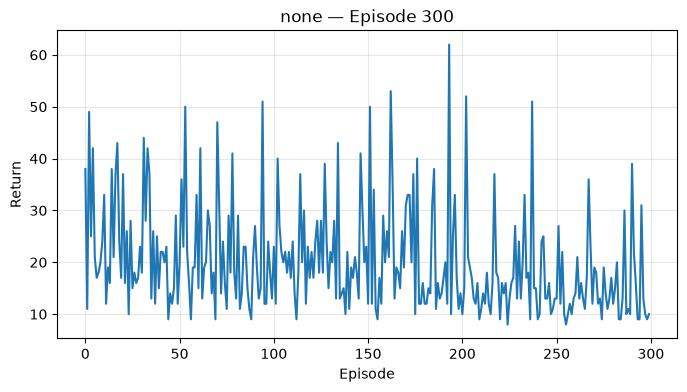

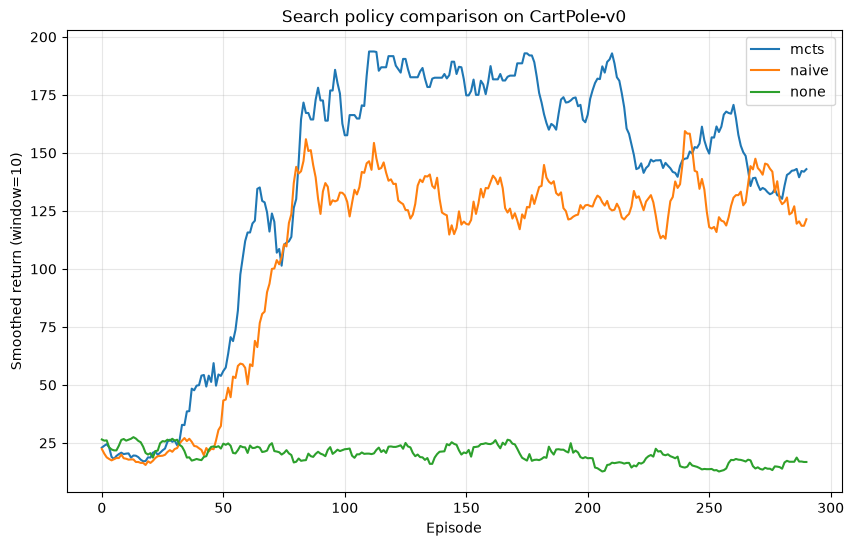

In [22]:
results = {}
for st in ["mcts", "naive", "none"]:
    print(f"\n=== Training agent with search_type = {st} ===")
    results[st] = train_agent(search_type=st, num_episodes=300, verbose=True)

plt.figure(figsize=(10, 6))
for st, returns in results.items():
    window = 10
    smoothed = np.convolve(returns, np.ones(window)/window, mode="valid")
    plt.plot(smoothed, label=st)
plt.title("Search policy comparison on CartPole-v0")
plt.xlabel("Episode")
plt.ylabel("Smoothed return (window=10)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 🔍 Discussion Questions *(answered)*

1. **Which search method converges fastest? Why might that be?**  
   In small discrete problems like CartPole, MCTS often learns with better early decisions because it uses the policy/value prior plus simulated latent rollouts before selecting an action. Naive search can also help, but it expands every possible action sequence uniformly and does not focus computation on promising branches. No-search is usually fastest per action but often needs more real episodes because it acts only from the current policy head.

2. **What is the wall-clock cost of MCTS vs. naive search vs. no search per episode? How does this scale with the action space?**  
   No-search is cheapest: one representation pass and one prediction pass, so its action-selection cost is approximately constant in the search depth. MCTS costs roughly `num_simulations × search_depth` recurrent model calls, but it allocates simulations adaptively using PUCT. Naive depth search costs `O(|A|^d)` model expansions for branching factor `|A|` and depth `d`, so it becomes expensive very quickly as either the number of actions or the depth increases.

3. **What happens if you increase `num_simulations` for MCTS? Is there a point of diminishing returns?**  
   Increasing `num_simulations` usually improves action selection because visit counts become more informative and the tree explores more alternatives. However, after enough simulations, extra computation often gives only small policy improvements. The point of diminishing returns depends on model quality: if the learned dynamics/value model is inaccurate, more search may even amplify model errors.

4. **Why does MuZero work even though the dynamics model is never trained to predict raw observations?**  
   MuZero only needs a latent model that is useful for planning. The representation and dynamics networks are trained so that their latent states predict rewards, values, and policies after unrolling. Therefore, the latent state does not need to reconstruct pixels or raw observations; it only needs to preserve the information relevant for control.

5. **How would you modify this code to run on a more complex environment such as LunarLander or Atari? Which components would need the most work?**  
   For LunarLander, the same MLP structure may work with adjusted hyperparameters, more training, and possibly reward/value normalization. For Atari, the representation network should become a CNN over stacked image frames, replay storage must handle large image observations efficiently, and the model/prediction heads need larger capacity. The most work would be in scaling the representation network, stabilizing training, tuning MCTS budget, and improving target/value normalization.

## ✅ Submission Checklist

Before submitting, make sure:

- [ ] All `TODO` blocks are filled in.
- [ ] The networks (`RepresentationNet`, `DynamicsNet`, `PredictionNet`) instantiate without errors.
- [ ] `MCTS.run(...)` returns visit counts whose sum equals `num_simulations`.
- [ ] `naive_depth_search(...)` returns a valid action (`int`) and a finite value.
- [ ] `train_agent(search_type="mcts")` runs end-to-end and produces a non-trivial learning curve.
- [ ] All three search types are compared in the final plot.
- [ ] The discussion questions are answered.

Good luck! 🌳